# RBERS — V4: Component-Parameterized Regenerative Braking Model

**Purpose:** upgrade V3 from a fixed recovery assumption to a physically constrained, component-parameterized reduced-order model.

**Architecture:** Vehicle deceleration → front-axle PMSM generator → 3-phase rectifier → DC link → bidirectional buck-boost → ultracapacitor → LFP battery.

**Important:** V4 is not yet a switching-level MOSFET simulation. All values marked `ASSUMPTION` should be replaced by actual component data in V5.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. VEHICLE + DRIVE-CYCLE ASSUMPTIONS
# ============================================================

mass_kg = 700.0
cruise_speed_kmh = 25.0
braking_events_per_hour = 50

cycle_time_s = 3600.0 / braking_events_per_hour
accel_time_s = 10.0
cruise_time_s = 52.0
brake_time_s = cycle_time_s - accel_time_s - cruise_time_s

wheel_radius_m = 0.30
gear_ratio = 1.0

Cd = 0.8
frontal_area_m2 = 2.0
air_density_kg_m3 = 1.225
rolling_resistance = 0.015
g = 9.81

# ============================================================
# 2. ELECTRICAL / COMPONENT ASSUMPTIONS
# ============================================================

# PMSM / generator
regen_power_limit_kw = 4.0
regen_peak_torque_nm = 80.0
regen_min_speed_kmh = 3.0
motor_generator_efficiency = 0.90

# 3-phase rectifier
rectifier_efficiency = 0.97

# Bidirectional buck-boost
converter_charge_limit_kw = 4.0
converter_discharge_limit_kw = 1.5
converter_charge_efficiency = 0.95
converter_discharge_efficiency = 0.95

# Ultracapacitor
uc_capacitance_f = 150.0
uc_initial_voltage_v = 30.0
uc_min_voltage_v = 30.0
uc_max_voltage_v = 60.0

# LFP battery / BMS
battery_nominal_voltage_v = 60.0
battery_capacity_ah = 100.0
battery_initial_soc = 0.50
battery_min_soc = 0.10
battery_max_soc = 0.95
battery_max_charge_current_a = 30.0

# Simulation
dt = 0.02
t = np.arange(0.0, 3600.0, dt)

print("V4 initialized")
print(f"Cycle time: {cycle_time_s:.1f} s")
print(f"Braking events/hour: {braking_events_per_hour}")
print(f"Brake duration/event: {brake_time_s:.1f} s")


V4 initialized
Cycle time: 72.0 s
Braking events/hour: 50
Brake duration/event: 10.0 s


## 3. Generate the 1-hour stop-go drive cycle

Distance in 1 hour: 21.53 km
Average speed: 21.53 km/h


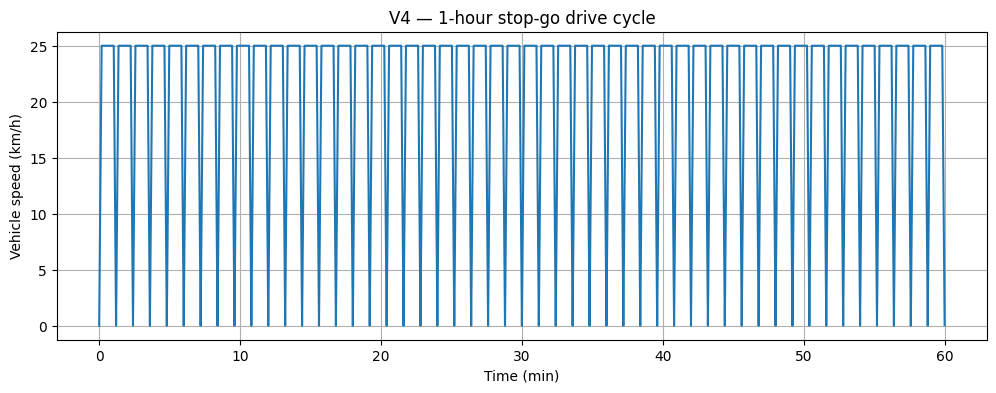

In [2]:
speed_kmh = np.zeros_like(t)

for i, ti in enumerate(t):
    phase = ti % cycle_time_s

    if phase < accel_time_s:
        speed_kmh[i] = cruise_speed_kmh * phase / accel_time_s
    elif phase < accel_time_s + cruise_time_s:
        speed_kmh[i] = cruise_speed_kmh
    else:
        brake_phase = phase - accel_time_s - cruise_time_s
        speed_kmh[i] = cruise_speed_kmh * (1.0 - brake_phase / brake_time_s)

speed_ms = speed_kmh / 3.6
acceleration_ms2 = np.gradient(speed_ms, dt)

distance_km = np.trapezoid(speed_ms, t) / 1000.0
average_speed_kmh = distance_km / 1.0

print(f"Distance in 1 hour: {distance_km:.2f} km")
print(f"Average speed: {average_speed_kmh:.2f} km/h")

plt.figure(figsize=(12, 4))
plt.plot(t / 60.0, speed_kmh)
plt.xlabel("Time (min)")
plt.ylabel("Vehicle speed (km/h)")
plt.title("V4 — 1-hour stop-go drive cycle")
plt.grid(True)
plt.show()


## 4. Mechanical braking demand
Only vehicle inertial deceleration energy is treated as potentially recoverable.

In [3]:
P_brake_mech_w = np.maximum(-mass_kg * acceleration_ms2 * speed_ms, 0.0)

mechanical_braking_energy_wh = np.trapezoid(P_brake_mech_w, t) / 3600.0
braking_energy_per_event_wh = mechanical_braking_energy_wh / braking_events_per_hour

print(f"Mechanical braking energy available: {mechanical_braking_energy_wh:.2f} Wh/hour")
print(f"Mechanical braking energy per event: {braking_energy_per_event_wh:.2f} Wh")
print(f"Peak mechanical braking power: {P_brake_mech_w.max()/1000.0:.2f} kW")


Mechanical braking energy available: 234.43 Wh/hour
Mechanical braking energy per event: 4.69 Wh
Peak mechanical braking power: 3.37 kW


## 5. Reduced-order PMSM regenerative generator

Mechanical energy captured by PMSM: 126.95 Wh/hour
Generator electrical energy: 114.25 Wh/hour
Mechanical capture fraction: 54.15%


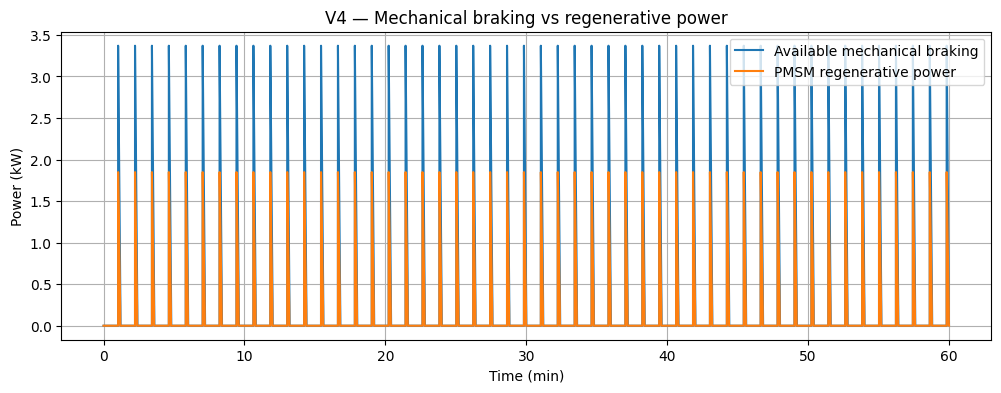

In [4]:
omega_rad_s = np.where(
    speed_ms > 0.0,
    speed_ms / wheel_radius_m * gear_ratio,
    0.0
)

required_regen_torque_nm = np.where(
    omega_rad_s > 1e-9,
    P_brake_mech_w / np.maximum(omega_rad_s, 1e-9),
    0.0
)

regen_torque_nm = np.minimum(required_regen_torque_nm, regen_peak_torque_nm)

regen_power_from_torque_w = regen_torque_nm * omega_rad_s

regen_mechanical_power_w = np.minimum(
    np.minimum(P_brake_mech_w, regen_power_from_torque_w),
    regen_power_limit_kw * 1000.0
)

regen_mechanical_power_w = np.where(
    speed_kmh >= regen_min_speed_kmh,
    regen_mechanical_power_w,
    0.0
)

generator_electrical_power_w = (
    regen_mechanical_power_w * motor_generator_efficiency
)

mechanical_regen_energy_wh = np.trapezoid(
    regen_mechanical_power_w, t
) / 3600.0

generator_electrical_energy_wh = np.trapezoid(
    generator_electrical_power_w, t
) / 3600.0

print(f"Mechanical energy captured by PMSM: {mechanical_regen_energy_wh:.2f} Wh/hour")
print(f"Generator electrical energy: {generator_electrical_energy_wh:.2f} Wh/hour")
print(f"Mechanical capture fraction: "
      f"{100.0 * mechanical_regen_energy_wh / mechanical_braking_energy_wh:.2f}%")

plt.figure(figsize=(12, 4))
plt.plot(t/60.0, P_brake_mech_w/1000.0, label="Available mechanical braking")
plt.plot(t/60.0, regen_mechanical_power_w/1000.0, label="PMSM regenerative power")
plt.xlabel("Time (min)")
plt.ylabel("Power (kW)")
plt.title("V4 — Mechanical braking vs regenerative power")
plt.legend()
plt.grid(True)
plt.show()


## 6. 3-phase rectifier

In [5]:
rectifier_input_power_w = generator_electrical_power_w
rectifier_output_power_w = rectifier_input_power_w * rectifier_efficiency

rectifier_input_energy_wh = np.trapezoid(rectifier_input_power_w, t) / 3600.0
rectifier_output_energy_wh = np.trapezoid(rectifier_output_power_w, t) / 3600.0
rectifier_loss_energy_wh = rectifier_input_energy_wh - rectifier_output_energy_wh

print(f"Energy into rectifier: {rectifier_input_energy_wh:.2f} Wh/hour")
print(f"Energy after rectifier: {rectifier_output_energy_wh:.2f} Wh/hour")
print(f"Rectifier losses: {rectifier_loss_energy_wh:.2f} Wh/hour")


Energy into rectifier: 114.25 Wh/hour
Energy after rectifier: 110.83 Wh/hour
Rectifier losses: 3.43 Wh/hour


## 7. Bidirectional converter + ultracapacitor + battery

In [6]:
uc_energy_j = 0.5 * uc_capacitance_f * uc_initial_voltage_v**2
uc_min_energy_j = 0.5 * uc_capacitance_f * uc_min_voltage_v**2
uc_max_energy_j = 0.5 * uc_capacitance_f * uc_max_voltage_v**2

battery_energy_received_wh = 0.0
battery_soc = battery_initial_soc

uc_energy_trace_j = np.zeros_like(t)
uc_voltage_trace_v = np.zeros_like(t)
battery_charge_power_trace_w = np.zeros_like(t)
battery_soc_trace = np.zeros_like(t)
converter_loss_power_trace_w = np.zeros_like(t)

battery_capacity_wh = battery_nominal_voltage_v * battery_capacity_ah
battery_charge_power_limit_w = battery_max_charge_current_a * battery_nominal_voltage_v

for i in range(len(t)):
    p_rect = rectifier_output_power_w[i]

    # ---- During regenerative braking: rectifier -> converter -> UC ----
    if p_rect > 1e-9:
        available_uc_capacity_power = max(
            (uc_max_energy_j - uc_energy_j) / dt, 0.0
        )

        p_converter_in = min(
            p_rect,
            converter_charge_limit_kw * 1000.0,
            available_uc_capacity_power
        )

        p_uc_stored = p_converter_in * converter_charge_efficiency
        uc_energy_j += p_uc_stored * dt

        converter_loss_power_trace_w[i] = (
            p_converter_in - p_uc_stored
        )

    # ---- Between braking events: UC -> converter -> battery ----
    else:
        available_uc_power = max(
            (uc_energy_j - uc_min_energy_j) / dt, 0.0
        )

        p_converter_out = min(
            available_uc_power,
            converter_discharge_limit_kw * 1000.0,
            battery_charge_power_limit_w
        )

        if p_converter_out > 0.0:
            uc_energy_j -= p_converter_out * dt

            p_battery = p_converter_out * converter_discharge_efficiency

            battery_energy_received_wh += p_battery * dt / 3600.0

            battery_soc += (
                p_battery * dt / 3600.0
            ) / battery_capacity_wh

            battery_soc = min(battery_soc, battery_max_soc)

            battery_charge_power_trace_w[i] = p_battery
            converter_loss_power_trace_w[i] = (
                p_converter_out - p_battery
            )

    uc_energy_j = np.clip(
        uc_energy_j,
        uc_min_energy_j,
        uc_max_energy_j
    )

    uc_energy_trace_j[i] = uc_energy_j
    uc_voltage_trace_v[i] = np.sqrt(
        2.0 * uc_energy_j / uc_capacitance_f
    )
    battery_soc_trace[i] = battery_soc

print(f"Battery energy received: {battery_energy_received_wh:.2f} Wh/hour")
print(f"Ultracap voltage range: "
      f"{uc_voltage_trace_v.min():.1f}–{uc_voltage_trace_v.max():.1f} V")
print(f"Battery SOC increase: "
      f"{(battery_soc_trace[-1] - battery_initial_soc)*100.0:.3f} percentage points")


Battery energy received: 98.50 Wh/hour
Ultracap voltage range: 30.0–31.6 V
Battery SOC increase: 1.642 percentage points


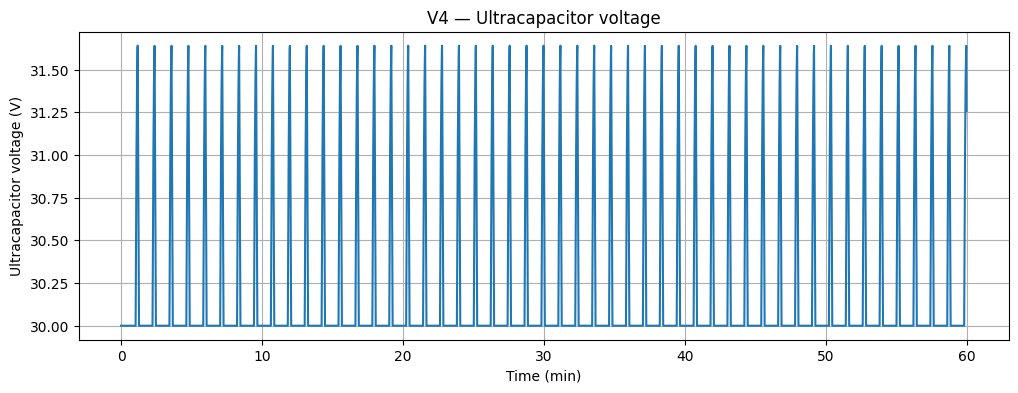

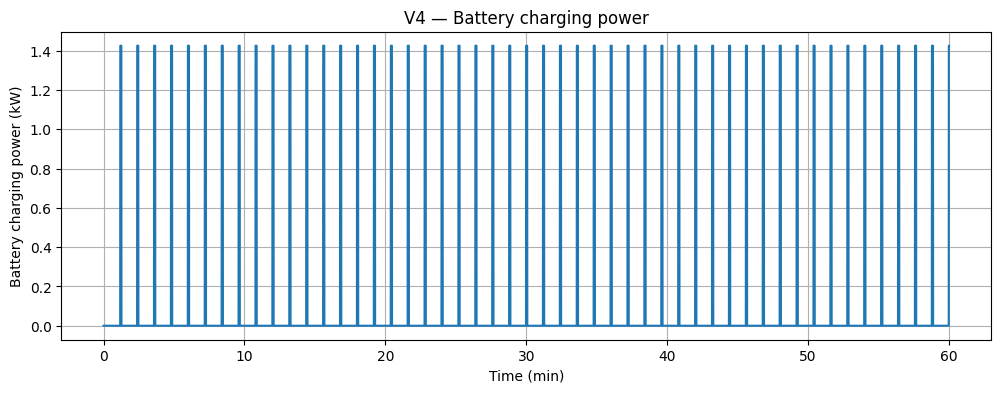

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(t/60.0, uc_voltage_trace_v)
plt.xlabel("Time (min)")
plt.ylabel("Ultracapacitor voltage (V)")
plt.title("V4 — Ultracapacitor voltage")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t/60.0, battery_charge_power_trace_w/1000.0)
plt.xlabel("Time (min)")
plt.ylabel("Battery charging power (kW)")
plt.title("V4 — Battery charging power")
plt.grid(True)
plt.show()


## 8. End-to-end recovery

In [8]:
mechanical_capture_fraction_pct = (
    100.0 * mechanical_regen_energy_wh / mechanical_braking_energy_wh
)

end_to_end_recovery_pct = (
    100.0 * battery_energy_received_wh / mechanical_braking_energy_wh
)

print("========== RBERS V4 RESULT ==========")
print(f"Braking events/hour: {braking_events_per_hour}")
print(f"Distance/hour: {distance_km:.2f} km")
print(f"Mechanical braking energy available: {mechanical_braking_energy_wh:.2f} Wh/h")
print(f"Mechanical energy captured by motor: {mechanical_regen_energy_wh:.2f} Wh/h")
print(f"Energy after rectifier: {rectifier_output_energy_wh:.2f} Wh/h")
print(f"Energy received by battery: {battery_energy_received_wh:.2f} Wh/h")
print(f"Mechanical capture fraction: {mechanical_capture_fraction_pct:.2f}%")
print(f"END-TO-END RECOVERY: {end_to_end_recovery_pct:.2f}%")
print("Proposal target band: 20–25%")
print("====================================")

# Energy-accounting sanity checks
assert battery_energy_received_wh <= rectifier_output_energy_wh + 1e-6
assert battery_energy_received_wh <= generator_electrical_energy_wh + 1e-6
assert uc_voltage_trace_v.min() >= uc_min_voltage_v - 1e-6
assert uc_voltage_trace_v.max() <= uc_max_voltage_v + 1e-6

print("Sanity checks: PASSED")


========== RBERS V4 RESULT ==========
Braking events/hour: 50
Distance/hour: 21.53 km
Mechanical braking energy available: 234.43 Wh/h
Mechanical energy captured by motor: 126.95 Wh/h
Energy after rectifier: 110.83 Wh/h
Energy received by battery: 98.50 Wh/h
Mechanical capture fraction: 54.15%
END-TO-END RECOVERY: 42.02%
Proposal target band: 20–25%
Sanity checks: PASSED


## 9. Sensitivity: regenerative power limit

,Regen power limit (kW),Battery received (Wh/h),End-to-end recovery (%)
0,1.0,77.43,33.03
1,2.0,98.50,42.02
2,3.0,98.50,42.02
3,4.0,98.50,42.02
4,5.0,98.50,42.02
5,6.0,98.50,42.02
6,7.0,98.50,42.02
7,8.0,98.50,42.02


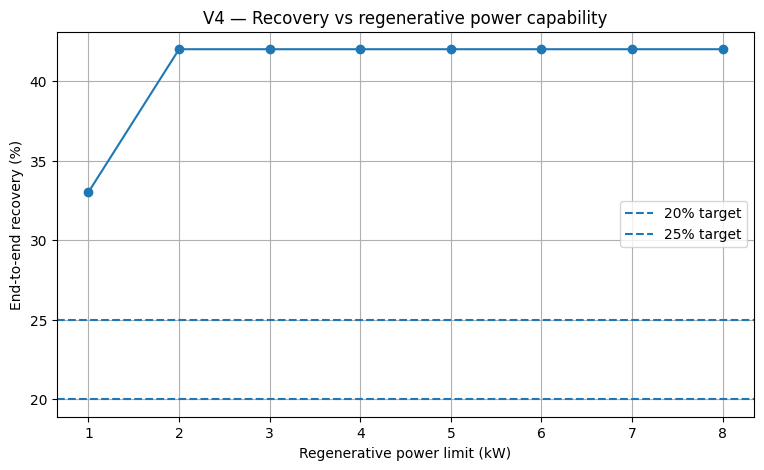

In [9]:
def simulate_recovery(regen_limit_kw):
    uc_e = uc_min_energy_j
    battery_received = 0.0

    for i in range(len(t)):
        omega = omega_rad_s[i]
        p_brake = P_brake_mech_w[i]

        if speed_kmh[i] < regen_min_speed_kmh or omega <= 1e-9:
            p_gen = 0.0
        else:
            tq_required = p_brake / omega
            tq = min(tq_required, regen_peak_torque_nm)
            p_gen = min(
                p_brake,
                tq * omega,
                regen_limit_kw * 1000.0
            )

        p_rect = p_gen * motor_generator_efficiency * rectifier_efficiency

        # Charge UC
        if p_rect > 0.0:
            p_in = min(
                p_rect,
                converter_charge_limit_kw * 1000.0,
                max((uc_max_energy_j - uc_e) / dt, 0.0)
            )
            uc_e += p_in * converter_charge_efficiency * dt

        # Discharge UC to battery
        else:
            p_out = min(
                max((uc_e - uc_min_energy_j) / dt, 0.0),
                converter_discharge_limit_kw * 1000.0,
                battery_charge_power_limit_w
            )
            uc_e -= p_out * dt
            battery_received += (
                p_out * converter_discharge_efficiency * dt / 3600.0
            )

        uc_e = np.clip(uc_e, uc_min_energy_j, uc_max_energy_j)

    recovery = 100.0 * battery_received / mechanical_braking_energy_wh
    return battery_received, recovery

limits_kw = np.arange(1.0, 8.1, 1.0)
rows = []

for limit in limits_kw:
    e_batt, recovery = simulate_recovery(limit)
    rows.append([limit, e_batt, recovery])

sensitivity_table = pd.DataFrame(
    rows,
    columns=[
        "Regen power limit (kW)",
        "Battery received (Wh/h)",
        "End-to-end recovery (%)"
    ]
)

display(sensitivity_table.round(2))

plt.figure(figsize=(9, 5))
plt.plot(
    sensitivity_table["Regen power limit (kW)"],
    sensitivity_table["End-to-end recovery (%)"],
    marker="o"
)
plt.axhline(20.0, linestyle="--", label="20% target")
plt.axhline(25.0, linestyle="--", label="25% target")
plt.xlabel("Regenerative power limit (kW)")
plt.ylabel("End-to-end recovery (%)")
plt.title("V4 — Recovery vs regenerative power capability")
plt.legend()
plt.grid(True)
plt.show()


## 10. V5 data required

Replace assumptions with actual component/datasheet/test values:

**Vehicle:** exact mass, wheel radius, gear ratio, real speed/acceleration cycle, Cd/frontal area.

**PMSM:** exact model, voltage, rated/peak power, torque-speed curve, RPM, pole pairs, phase resistance, Ld, Lq, flux linkage/back-EMF constant, torque constant, efficiency map, thermal limits.

**Rectifier:** topology, MOSFET model, RDS(on), voltage/current ratings, switching frequency, dead time, gate resistance, diode/body-diode characteristics if relevant.

**DC link:** capacitance, ESR, voltage rating, ripple-current rating.

**Bidirectional buck-boost:** topology, MOSFETs, inductor, switching frequency, current limits, voltage limits, efficiency map, controller/gate-drive details.

**Ultracapacitor:** exact module/cell, capacitance, voltage, ESR, leakage, continuous/peak current, temperature limits, series/parallel configuration.

**Battery:** exact LFP cell, S/P configuration, nominal/max/min voltage, capacity, charge/discharge limits, internal resistance, OCV-SOC curve, temperature dependence.

**BMS:** exact ADBMS6815 configuration, cell limits, current limits, temperature limits, balancing strategy, NTC locations.

**STM32/IMU:** exact parts, sampling rate, filtering, deceleration threshold, control logic, CAN/PWM interfaces.

**Experimental:** dynamometer torque/RPM, phase voltage/current, DC-link voltage/current, UC voltage/current, battery voltage/current, temperatures, timestamps.

V5 should then move from average efficiencies toward electrical waveforms and component losses.
